In [2]:
import numpy as np
import scipy
import pandas as pd
import matplotlib
#matplotlib.use("TkAgg")
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
import importlib
import lattice
import kmc
import loading as ld
import pickle
importlib.reload(lattice)
importlib.reload(kmc)

#########################################
# Testing analytic LD in regular lattices
# - random fixed dipoles
# - should return effective kappa of 0.476
##########################################
tau = 1
rf = 1
r0=1
n=30

LOAD_FIXED_KAPPA=False
FIXED_KAPPA = 0.476 #2/3
save = False
cutoff = r0
krot_dip = 0
PBC = [0,1]
L = r0*np.array([n,n])
nrounds = 2000#00
dim = len(L)

Ds,Lds = [],[]

images = 100
outs = []
for i in range(images):
    syst = ld.System(save=save,RF=rf,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_dip)
    syst.make_lattice()
    results = Parallel(n_jobs=10,verbose=0)(delayed(kmc.kmc_run_fluor)(syst) for _ in range(nrounds))
    out_dict = kmc.process_results(results,dim=len(L),RF=rf,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)
    outs.append(out_dict)

with open(f"out_kmc2D_{rf}_{tau}.pkl", "wb") as f:
    pickle.dump(outs, f)


this program run with <Kappa^2> = 0.66604
DONE LOADING LATTICE
Dana = 0.48 Dlasttime = 0.51 Dmean = 0.59
LDana =0.69 LDcalc=0.71 LD_d=0.77
this program run with <Kappa^2> = 0.67076
DONE LOADING LATTICE
Dana = 0.48 Dlasttime = 0.49 Dmean = 0.52
LDana =0.69 LDcalc=0.71 LD_d=0.72
this program run with <Kappa^2> = 0.67609
DONE LOADING LATTICE
Dana = 0.48 Dlasttime = 0.49 Dmean = 0.53
LDana =0.69 LDcalc=0.70 LD_d=0.73
this program run with <Kappa^2> = 0.67304
DONE LOADING LATTICE
Dana = 0.48 Dlasttime = 0.47 Dmean = 0.51
LDana =0.69 LDcalc=0.68 LD_d=0.72
this program run with <Kappa^2> = 0.68176
DONE LOADING LATTICE
Dana = 0.48 Dlasttime = 0.51 Dmean = 0.54
LDana =0.69 LDcalc=0.70 LD_d=0.74
this program run with <Kappa^2> = 0.66324
DONE LOADING LATTICE
Dana = 0.48 Dlasttime = 0.47 Dmean = 0.53
LDana =0.69 LDcalc=0.68 LD_d=0.73
this program run with <Kappa^2> = 0.66164
DONE LOADING LATTICE
Dana = 0.48 Dlasttime = 0.44 Dmean = 0.52
LDana =0.69 LDcalc=0.67 LD_d=0.72
this program run with <Kapp

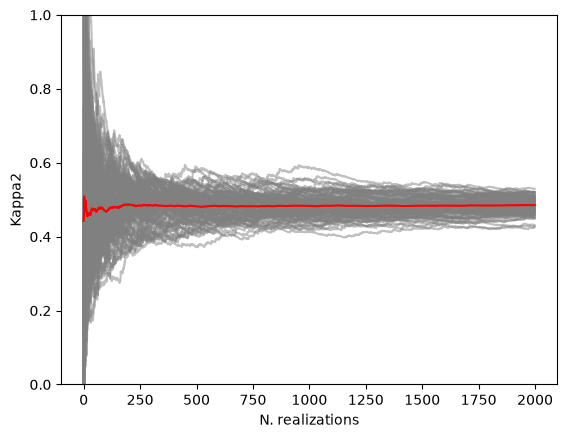

0.4855015007503752


In [4]:
import numpy as np
import scipy
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import importlib
import pickle

##########################################
tau = 1
rf = 1
r0=1
n=30
nrounds = 2000#00
images = 100
with open(f"out_kmc2D_{rf}_{tau}.pkl", "rb") as f:
    outs = pickle.load(f)

D_nokappa=(1/tau)*(((rf)**6)/(r0**4))
cums = np.zeros(nrounds)
Ld_ana_wihtoutkappa = (rf**3)/(r0**2)

for i in range(images):
    out_dict = outs[i]
    Ds = np.array([x for x in out_dict['D']])
    Dlist = np.array([x[0] for x in out_dict['Dlist']])
    kappa2_from_out = np.array([x for x in out_dict['kappa2_list_MSD']])
    mean_from_image = np.array([ np.mean(kappa2_from_out[:n]) for n in range(1,len(kappa2_from_out)) ])
    plt.plot(np.arange(len(mean_from_image)),mean_from_image,c='grey',alpha=0.5)

    
    cums+=kappa2_from_out#Lds
cums  = cums/images
means = np.array([ np.mean(cums[:n]) for n in range(1,len(cums)) ])

plt.xlabel('N. realizations')
plt.ylabel('Kappa2')
plt.ylim(0,1)
plt.plot(np.arange(len(means)),means,c='r')
plt.show()
print(means[-1])

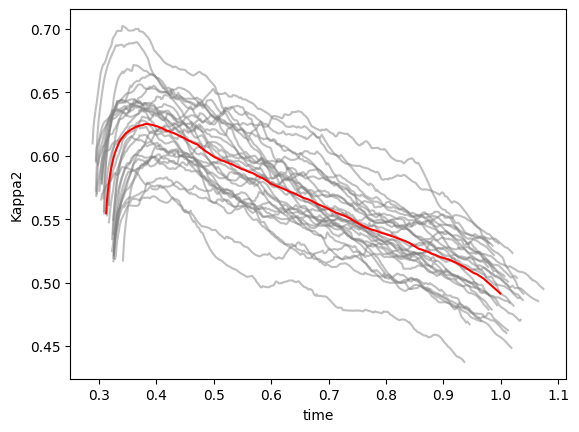

0.4914498478647672


In [9]:
#plotting kappa but during time

with open(f"out_kmc2D_{rf}_{tau}.pkl", "rb") as f:
    outs=pickle.load(f)

nmeas = 500
Ttot = np.zeros(nmeas)
kappas=np.zeros(nmeas)

for i in range(images):
    out_dict = outs[i]
    t,k =  out_dict['Dtime']
    plt.plot(t,k,c='gray',alpha=0.5)
    Ttot +=t
    kappas+= k
    
Ttot   = Ttot/images
kappas = kappas/images
#means = np.array([ np.mean(cums[:n]) for n in range(1,len(cums)) ])
#kappa2=(means/Ld_ana_wihtoutkappa)**2

#kappa2=(means/D_nokappa)
plt.xlabel('time')
plt.ylabel('Kappa2')
plt.plot(Ttot,kappas,c='r')
plt.show()
print(kappas[-1])